In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path
import nltk
pd.options.display.max_columns = 100

import google_conf


In [30]:
k10plus_googlesheet = google_conf.setup(
    sheet_url="https://docs.google.com/spreadsheets/d/1EUQc-yGT-PC0PYrwwluOtdCoRbhQ7THbWo7HD2ks3sI/edit?usp=sharing",
    service_account_path="../../../ServiceAccountsKey.json")

In [5]:
DATA_DIR = next(
    (
        folder / "data/k10plus"
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "k10plus" / "export.json").exists()
    ),
    None,
)
assert DATA_DIR is not None, "data/k10plus/export.json not found above the working directory"
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /home/jupyter-vojta/notebooks/biblical-books/data/k10plus


In [6]:
import pyarrow.parquet as pq

path = DATA_DIR / "books_centurn_enggerfre.parquet"

# The file's pandas metadata records list columns as "list<element: string>[pyarrow]",
# which pandas feeds to np.dtype() and rejects. Drop the metadata, keep the data.
books_centurn_enggerfre = pq.read_table(path).replace_schema_metadata(None).to_pandas()

print(books_centurn_enggerfre.shape)
books_centurn_enggerfre.dtypes.value_counts()

(116001, 44)


object    24
str       18
int32      1
bool       1
Name: count, dtype: int64

In [7]:
books_centurn_enggerfre.head(10)

,record_id,source_url,leader,record_type,bibliographic_level,title,subtitle,full_title,responsibility,publication_statement,date_text,edition,extent,abstract,date_type,first_seen,last_seen,authors,editors,contributors,languages,isbns,issns,dois,publishers,publication_places,subjects,subject_authority_ids,ddc,lcc,other_classifications,series,urls,related_record_ids,notes,matched_queries,name_authority_ids,authority_ids,contributor_types,publication_year,is_textual_monograph,contributor_records,subjects_structured,title_cleaned
0,010017054,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Du gibst weiten Raum meinen Schritten,Lebensmut aus der Bibel,Du gibst weiten Raum meinen Schritten: Lebensm...,Walter Strolz,Freiburg im Breisgau [u.a.] Herder 1980,1980,,128 S,,s,2026-11-18T13:19:28.460603+00:00,2026-11-18T13:19:28.460603+00:00,"[Strolz, Walter]",[],"[Strolz, Walter]",[ger],[3451191326],[],[],[Herder],[Freiburg im Breisgau [u.a.]],"[Bibel, Betrachtung]","[4006406-2, 4280396-2, 4071867-0]",[],[],"[02a sdnb, 1 ssgn, BT 2050 rvk (DE-625)rvk/167...",[],[],[],[],[subject_bibel],[124873324],"[124873324, 4006406-2, 4280396-2, 4071867-0]",[aut],1980,True,"[{'sequence': 1, 'marc_tag': '100', 'is_primar...","[{'sequence': 1, 'marc_tag': '630', 'entity_ty...",weit raum schritt lebensmut bibel
1,010021817,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Mittelpunkt Bibel,Ulrich Fick zum 60. Geburtstag,Mittelpunkt Bibel: Ulrich Fick zum 60. Geburtstag,hrsg. von Siegfried Meurer,Stuttgart Dt. Bibelges. 1983,1983,,"336 S. Ill., Notenbeisp.",,s,2026-11-18T11:21:03.383857+00:00,2026-11-18T13:16:12.965666+00:00,[],[],"[Meurer, Siegfried, Fick, Ulrich]","[ger, eng]",[3438062208],[],[],[Dt. Bibelges.],[Stuttgart],[Aufsatzsammlung],[4006406-2],"[220, 220.6]",[],"[12 sdnb, 0 ssgn, 11.30 bkl]","[Die Bibel in der Welt 20, Die Bibel in der We...",[],[],[Ill. ist Photogr. d. Gefeierten auf d. Vortit...,"[ddc_bible, subject_bibel]","[123791235, 118687042]","[123791235, 118687042, 4006406-2]","[oth, hnr]",1983,True,"[{'sequence': 1, 'marc_tag': '700', 'is_primar...","[{'sequence': 1, 'marc_tag': '689', 'entity_ty...",mittelpunkt bibel ulrich fick 60 geburtstag
2,010022643,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Die Bibel oder die ganze heilige Schrift des A...,,Die Bibel oder die ganze heilige Schrift des A...,nach der Übers. Martin Luthers,Stuttgart Dt. Bibelstiftung 1982,1982,,Getr. Zählung Kt,,s,2026-11-18T13:17:16.897027+00:00,2026-11-18T13:17:16.897027+00:00,[],[],"[Luther, Martin]",[ger],"[3438015315, 3438015323, 3438015366, 3438015374]",[],[],[Dt. Bibelstiftung],[Stuttgart],[],[4006406-2],[],[],[11.31 bkl],[],[],[],[Rev. Text 1975],[subject_bibel],[118575449],"[118575449, 4006406-2]",[oth],1982,True,"[{'sequence': 1, 'marc_tag': '700', 'is_primar...","[{'sequence': 1, 'marc_tag': '689', 'entity_ty...",bibel ganz heilig schrift alte neu testament
3,010037403,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Frauenbefreiung,biblische und theologische Argumente,Frauenbefreiung: biblische und theologische Ar...,herausgegeben von Elisabeth Moltmann-Wendel,München Kaiser 1986,1986,"4., veränderte Auflage",240 Seiten 21 cm,,s,2026-11-18T21:41:00.650234+00:00,2026-11-18T21:41:00.650234+00:00,[],"[Moltmann-Wendel, Elisabeth]","[Moltmann-Wendel, Elisabeth]",[ger],[3459014458],[],[],[Kaiser],[München],[Aufsatzsammlung],"[4011882-4, 4071428-7, 4030702-5, 4113537-4]",[],[],"[12 64 sdnb, BH 3820 rvk (DE-625)rvk/11688:, 1...",[Gesellschaft und Theologie : Systematische Be...,[],[],"[1. Aufl. unter dem Titel ""Menschenrechte für ...",[title_biblisch],[118984896],"[118984896, 4011882-4, 4071428-7, 4030702-5, 4...",[edt],1986,True,"[{'sequence': 1, 'marc_tag': '700', 'is_primar...","[{'sequence': 1, 'marc_tag': '689', 'entity_ty...",frauenbefreiung biblisch theologisch argument
4,010039007,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 2c 4500,a,m,Psalm 23,aus der Sic

In [8]:
import ast


def parse_list(value):
    """Normalise a list-like cell value (string or existing sequence) into a list."""
    if value is None or value is pd.NA:
        return []
    if isinstance(value, float) and value != value:   # NaN (scalar only)
        return []
    if hasattr(value, "tolist") and not isinstance(value, (str, bytes, bytearray)):
        return list(value.tolist())                   # numpy / pyarrow arrays
    if isinstance(value, (bytes, bytearray)):
        value = value.decode("utf-8", "replace")
    if not isinstance(value, str):
        try:
            return list(value)                        # list / tuple / other iterable
        except TypeError:
            return []                                 # number, ...

    text = value.replace("\x00", "").strip()          # null bytes raise SyntaxError
    if not text:
        return []

    try:
        parsed = ast.literal_eval(text)
    except (ValueError, SyntaxError):
        return [p.strip().strip("'\"") for p in text.strip("[]").split(",") if p.strip()]
    return list(parsed) if isinstance(parsed, (list, tuple, set)) else [parsed]


books_centurn_enggerfre["languages"] = books_centurn_enggerfre["languages"].apply(parse_list)
books_centurn_enggerfre["languages"].head(10).map(type)

0    <class 'list'>
1    <class 'list'>
2    <class 'list'>
3    <class 'list'>
4    <class 'list'>
5    <class 'list'>
6    <class 'list'>
7    <class 'list'>
8    <class 'list'>
9    <class 'list'>
Name: languages, dtype: object

In [9]:
books_centurn_enggerfre["language_first"] = books_centurn_enggerfre["languages"].apply(
    lambda x: x[0] if len(x) else None
)

In [10]:
books_centurn_enggerfre["language_first"].value_counts()

language_first
eng    63992
ger    46482
fre     5527
Name: count, dtype: int64

In [11]:
books_centurn_enggerfre.columns

Index(['record_id', 'source_url', 'leader', 'record_type',
       'bibliographic_level', 'title', 'subtitle', 'full_title',
       'responsibility', 'publication_statement', 'date_text', 'edition',
       'extent', 'abstract', 'date_type', 'first_seen', 'last_seen', 'authors',
       'editors', 'contributors', 'languages', 'isbns', 'issns', 'dois',
       'publishers', 'publication_places', 'subjects', 'subject_authority_ids',
       'ddc', 'lcc', 'other_classifications', 'series', 'urls',
       'related_record_ids', 'notes', 'matched_queries', 'name_authority_ids',
       'authority_ids', 'contributor_types', 'publication_year',
       'is_textual_monograph', 'contributor_records', 'subjects_structured',
       'title_cleaned', 'language_first'],
      dtype='str')

In [12]:
books_sample = books_centurn_enggerfre[books_centurn_enggerfre["language_first"]=="eng"]
len(books_sample)

63992

In [13]:
nltk.FreqDist(" ".join(books_sample["title_cleaned"].tolist()).split()).most_common(20)

[('biblical', 8452),
 ('bible', 8398),
 ('new', 5697),
 ('testament', 5645),
 ('study', 4811),
 ('gospel', 4101),
 ('commentary', 3559),
 ('book', 3478),
 ('paul', 3275),
 ('god', 2974),
 ('jesus', 2961),
 ('hebrew', 2703),
 ('old', 2583),
 ('theology', 2579),
 ('early', 2576),
 ('text', 2492),
 ('christian', 2434),
 ('john', 2345),
 ('ancient', 2297),
 ('history', 2247)]

In [14]:
step = 10
for period in range(1980, 2030, step):
    books_sample_period = books_centurn_enggerfre[(books_centurn_enggerfre["publication_year"] >= period) & (books_centurn_enggerfre["publication_year"] < period + step)]
    print(f"Period: {period}-{period + step - 1}, Count: {len(books_sample_period)}")
    nltk.FreqDist(" ".join(books_sample_period["title_cleaned"].tolist()).split()).most_common(10)

Period: 1980-1989, Count: 16256
Period: 1990-1999, Count: 21404
Period: 2000-2009, Count: 25141
Period: 2010-2019, Count: 33009
Period: 2020-2029, Count: 20191


In [15]:
data_samples = {}
step = 10
for language in ["eng", "ger", "fre"]:
    books_sample_lang = books_centurn_enggerfre[books_centurn_enggerfre["language_first"]==language] 
    for period in range(1980, 2030, step):
        books_sample_period = books_sample_lang[(books_sample_lang["publication_year"] >= period) & (books_sample_lang["publication_year"] < period + step)]
        period_string = "-".join((str(period), str(period + step - 1)))
        data_samples["_".join((language, period_string))] = books_sample_period
data_samples.keys()

dict_keys(['eng_1980-1989', 'eng_1990-1999', 'eng_2000-2009', 'eng_2010-2019', 'eng_2020-2029', 'ger_1980-1989', 'ger_1990-1999', 'ger_2000-2009', 'ger_2010-2019', 'ger_2020-2029', 'fre_1980-1989', 'fre_1990-1999', 'fre_2000-2009', 'fre_2010-2019', 'fre_2020-2029'])

In [16]:
for sample in data_samples:
    print(f"{sample}: {len(data_samples[sample])} books")

eng_1980-1989: 7356 books
eng_1990-1999: 10760 books
eng_2000-2009: 13295 books
eng_2010-2019: 19666 books
eng_2020-2029: 12915 books
ger_1980-1989: 7816 books
ger_1990-1999: 9439 books
ger_2000-2009: 10588 books
ger_2010-2019: 12130 books
ger_2020-2029: 6509 books
fre_1980-1989: 1084 books
fre_1990-1999: 1205 books
fre_2000-2009: 1258 books
fre_2010-2019: 1213 books
fre_2020-2029: 767 books


In [25]:
freq_table_data = {}
n = 200
for name, books_sample in data_samples.items():
    print(name)
    raw_title_tokens = " ".join(books_sample["title"].dropna().tolist()).split()
    raw_sample_title_length = len(raw_title_tokens)
    sample_counts = nltk.FreqDist(" ".join(books_sample["title_cleaned"].dropna().tolist()).split()).most_common(n)
    sample_words = [tup[0] for tup in sample_counts]
    sample_counts = [tup[1] for tup in sample_counts]
    sample_freqs = [count / raw_sample_title_length for count in sample_counts]
    freq_table_data[name + "_words"] = sample_words
    freq_table_data[name + "_freqs"] = sample_freqs

eng_1980-1989
eng_1990-1999
eng_2000-2009
eng_2010-2019
eng_2020-2029
ger_1980-1989
ger_1990-1999
ger_2000-2009
ger_2010-2019
ger_2020-2029
fre_1980-1989
fre_1990-1999
fre_2000-2009
fre_2010-2019
fre_2020-2029


In [35]:
freq_table_data_df = pd.DataFrame(freq_table_data)
freq_table_data_df = freq_table_data_df.round(5)

In [37]:
google_conf.set_with_dataframe(k10plus_googlesheet.add_worksheet("freq_table_data", 1,1), freq_table_data_df)

KeyError: 'eng_2020-2026'

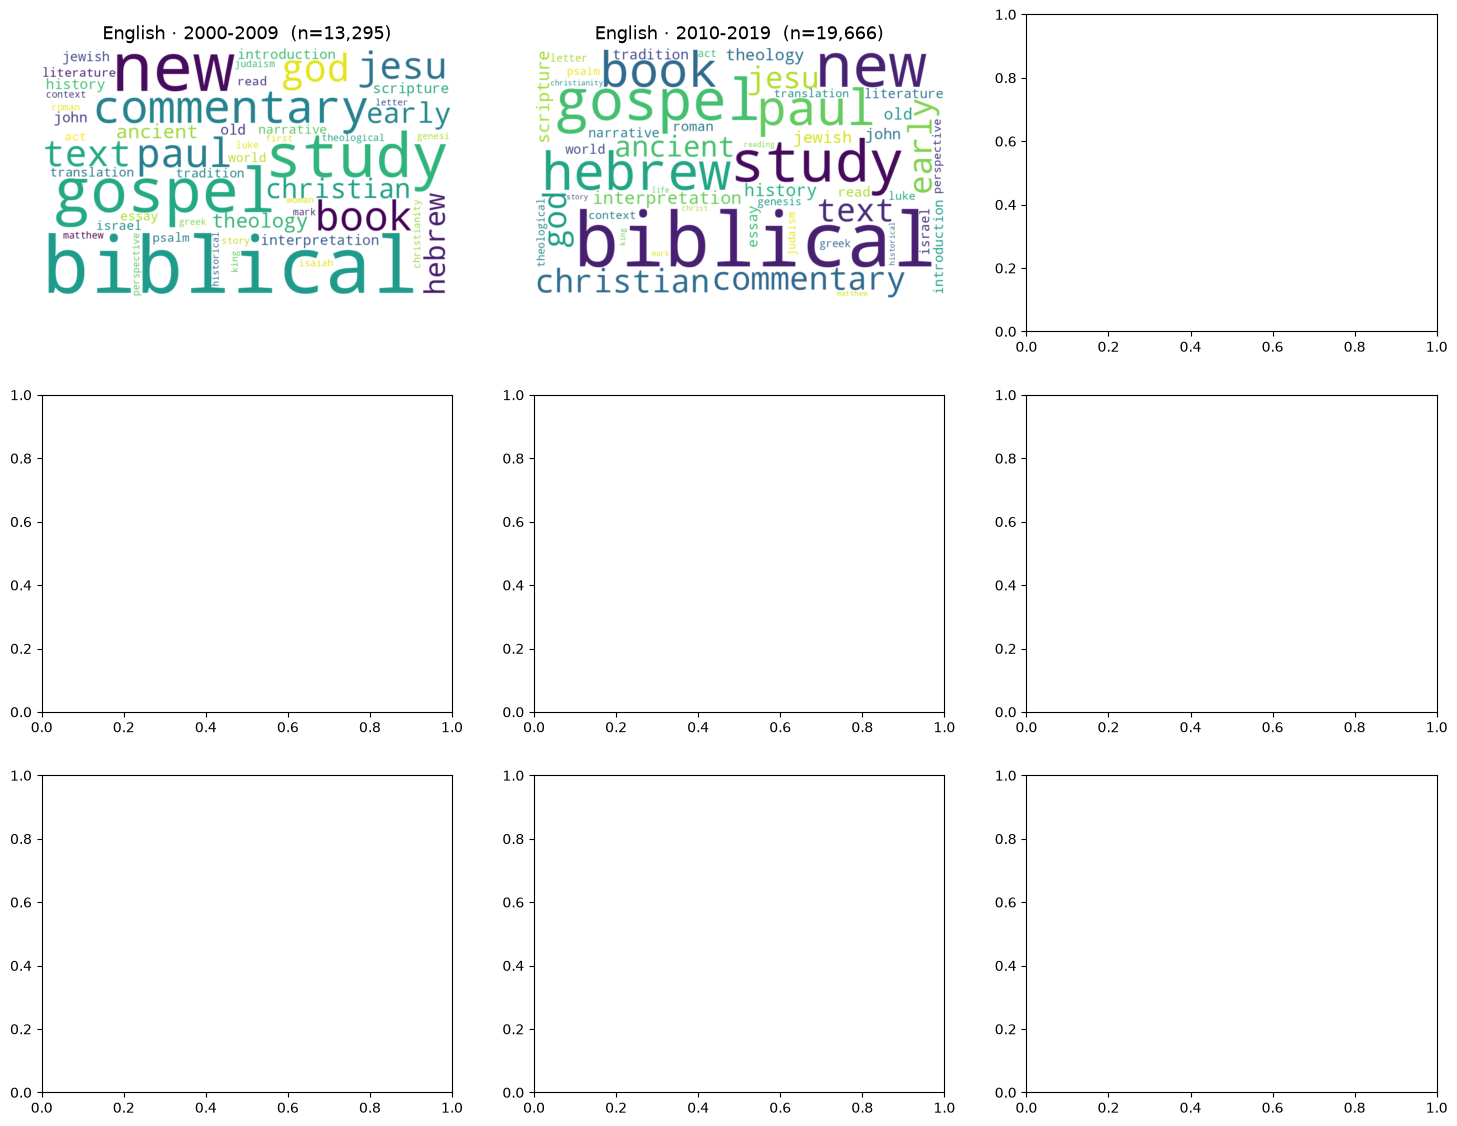

In [ ]:
from nltk.corpus import stopwords as nltk_stopwords

from wordcloud import WordCloud   # pip install wordcloud  if missing

# Per-language stopwords; falls back to an empty set if the nltk corpora are absent
try:
    STOPWORDS = {
        "eng": set(nltk_stopwords.words("english")),
        "ger": set(nltk_stopwords.words("german")),
        "fre": set(nltk_stopwords.words("french")),
    }
except Exception:
    STOPWORDS = {"eng": set(), "ger": set(), "fre": set()}

# Domain noise that would otherwise dominate every panel
COMMON_NOISE = {"bibel", "bible", "testament", "band", "bd", "vol", "edition"}
STOPWORDS = {lang: words | COMMON_NOISE for lang, words in STOPWORDS.items()}

# Wordcloud from freq_table_data_df (precomputed frequencies)
LANGS = ["eng", "ger", "fre"]
LANG_NAMES = {"eng": "English", "ger": "German", "fre": "French"}

# Extract unique decades from column names
decades_in_cols = sorted(set(col.split("_")[1] for col in freq_table_data_df.columns if "_" in col))

fig, axes = plt.subplots(3, len(decades_in_cols), figsize=(5*len(decades_in_cols), 11))

for row, lang in enumerate(LANGS):
    for col, decade in enumerate(decades_in_cols):
        ax = axes[row, col]
        
        words_col = f"{lang}_{decade}_words"
        freqs_col = f"{lang}_{decade}_freqs"
        
        if words_col in freq_table_data_df.columns and freqs_col in freq_table_data_df.columns:
            words = freq_table_data_df[words_col].dropna().tolist()
            freqs = freq_table_data_df[freqs_col].dropna().tolist()
            
            if words and freqs:
                frequencies = dict(zip(words, freqs))
                wc = WordCloud(
                    width=900, height=550,
                    background_color="white",
                    stopwords=STOPWORDS[lang],
                    collocations=False,
                    max_words=50,
                    relative_scaling=0.5,
                    random_state=42,
                ).generate_from_frequencies(frequencies)
                ax.imshow(wc, interpolation="bilinear")
                n_words = len(words)
            else:
                ax.text(0.5, 0.5, "no data", ha="center", va="center", fontsize=12)
                n_words = 0
        else:
            ax.text(0.5, 0.5, "no data", ha="center", va="center", fontsize=12)
            n_words = 0
        
        ax.set_title(f"{LANG_NAMES[lang]} · {decade}  (n={n_words})", fontsize=13)
        ax.axis("off")

fig.suptitle("Most frequent title words by language and decade", fontsize=16)
fig.tight_layout()
plt.show()

In [44]:
fig.savefig("../figures/wordclouds_by_language_decade.png", dpi=300)